# Task 3: Multimodal ML – Housing Price Prediction Using Images + Tabular Data

**DevelopersHub Corporation — AI/ML Engineering Advanced Internship**

---

## Problem Statement & Objective

Build a **multimodal ML pipeline** that:
1. Uses a **CNN (MobileNetV2)** to extract visual features from house images
2. Combines these image features with **tabular housing data**
3. Trains a **fusion regression model** to predict house prices
4. Evaluates performance using **MAE and RMSE**

**Datasets Used:**
- **Tabular:** House Prices – Advanced Regression Techniques (Kaggle)
- **Images:** House Rooms Image Dataset (Kaggle via kagglehub)

---

## Section 1: Environment Setup & Imports

In [1]:
!pip install kaggle kagglehub tensorflow scikit-learn pandas numpy matplotlib seaborn pillow -q

In [2]:
import os
import warnings
import zipfile
import random
import shutil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import seaborn as sns

from pathlib import Path
from PIL import Image

import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.impute import SimpleImputer
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.decomposition import PCA

warnings.filterwarnings('ignore')
tf.get_logger().setLevel('ERROR')

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
random.seed(SEED)

print(f"TensorFlow : {tf.__version__}")
print(f"NumPy      : {np.__version__}")
print(f"Pandas     : {pd.__version__}")
print("All imports successful!")

TensorFlow : 2.20.0
NumPy      : 2.0.2
Pandas     : 2.2.2
All imports successful!


---
## Section 2: Dataset Download

### 2A – Kaggle Credentials (Colab Secrets)

In [3]:
# Load Kaggle credentials from Colab Secrets
# Go to the key icon in the left sidebar -> add KAGGLE_USERNAME and KAGGLE_KEY
from google.colab import userdata

os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
os.environ["KAGGLE_KEY"]      = userdata.get("KAGGLE_KEY")

print("Kaggle credentials loaded!")
print(f"Logged in as: {os.environ['KAGGLE_USERNAME']}")

Kaggle credentials loaded!
Logged in as: muhammadshahzad26


### 2B – Download Tabular Dataset (House Prices)

In [4]:
from google.colab import files
print("Upload the zip file:")
uploaded = files.upload()

Upload the zip file:


Saving house-prices-advanced-regression-techniques.zip to house-prices-advanced-regression-techniques.zip


In [5]:
import zipfile
from pathlib import Path

TABULAR_DIR = Path("/content/data/tabular")
TABULAR_DIR.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile("house-prices-advanced-regression-techniques.zip", "r") as z:
    z.extractall(TABULAR_DIR)

print("Extracted files:")
for f in sorted(TABULAR_DIR.iterdir()):
    print(f"  {f.name}")


Extracted files:
  data_description.txt
  sample_submission.csv
  test.csv
  train.csv


In [6]:
TRAIN_CSV = TABULAR_DIR / "train.csv"
assert TRAIN_CSV.exists(), "train.csv not found!"
print(f"train.csv ready at: {TRAIN_CSV}")

train.csv ready at: /content/data/tabular/train.csv


In [7]:
df = pd.read_csv(TRAIN_CSV)
print(f"Dataset shape: {df.shape}")

Dataset shape: (1460, 81)


### 2C – Download Image Dataset (kagglehub)

In [8]:
# Download House Rooms Image Dataset via kagglehub
import kagglehub

print("Downloading House Rooms Image Dataset via kagglehub...")
kagglehub_path = kagglehub.dataset_download("robinreni/house-rooms-image-dataset")
print(f"Dataset downloaded to: {kagglehub_path}")

# Use the path returned by kagglehub directly as IMAGE_DIR
IMAGE_DIR = Path(kagglehub_path)

# Count all images recursively
all_images = (
    list(IMAGE_DIR.rglob("*.jpg")) +
    list(IMAGE_DIR.rglob("*.jpeg")) +
    list(IMAGE_DIR.rglob("*.png"))
)

print(f"\nTotal images found : {len(all_images)}")
print("Sample paths:")
for p in all_images[:5]:
    print(f"  {p}")

100%|██████████| 116M/116M [00:00<00:00, 172MB/s]

Extracting files...


Dataset downloaded to: /root/.cache/kagglehub/datasets/robinreni/house-rooms-image-dataset/versions/1

Total images found : 5250
Sample paths:
  /root/.cache/kagglehub/datasets/robinreni/house-rooms-image-dataset/versions/1/House_Room_Dataset/Bathroom/bath_363.jpg
  /root/.cache/kagglehub/datasets/robinreni/house-rooms-image-dataset/versions/1/House_Room_Dataset/Bathroom/bath_1230.jpg
  /root/.cache/kagglehub/datasets/robinreni/house-rooms-image-dataset/versions/1/House_Room_Dataset/Bathroom/bath_864.jpg
  /root/.cache/kagglehub/datasets/robinreni/house-rooms-image-dataset/versions/1/House_Room_Dataset/Bathroom/bath_775.jpg
  /root/.cache/kagglehub/datasets/robinreni/house-rooms-image-dataset/versions/1/House_Room_Dataset/Bathroom/bath_749.jpg


---
## Section 3: Tabular Data Loading & Exploratory Data Analysis

In [9]:
# Load Tabular Data — read directly from train.csv file (not the directory)
df = pd.read_csv(TRAIN_CSV)

print(f"Dataset shape: {df.shape}")
print(f"\nTarget variable (SalePrice) stats:")
print(df['SalePrice'].describe())
df.head()

Dataset shape: (1460, 81)

Target variable (SalePrice) stats:
count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


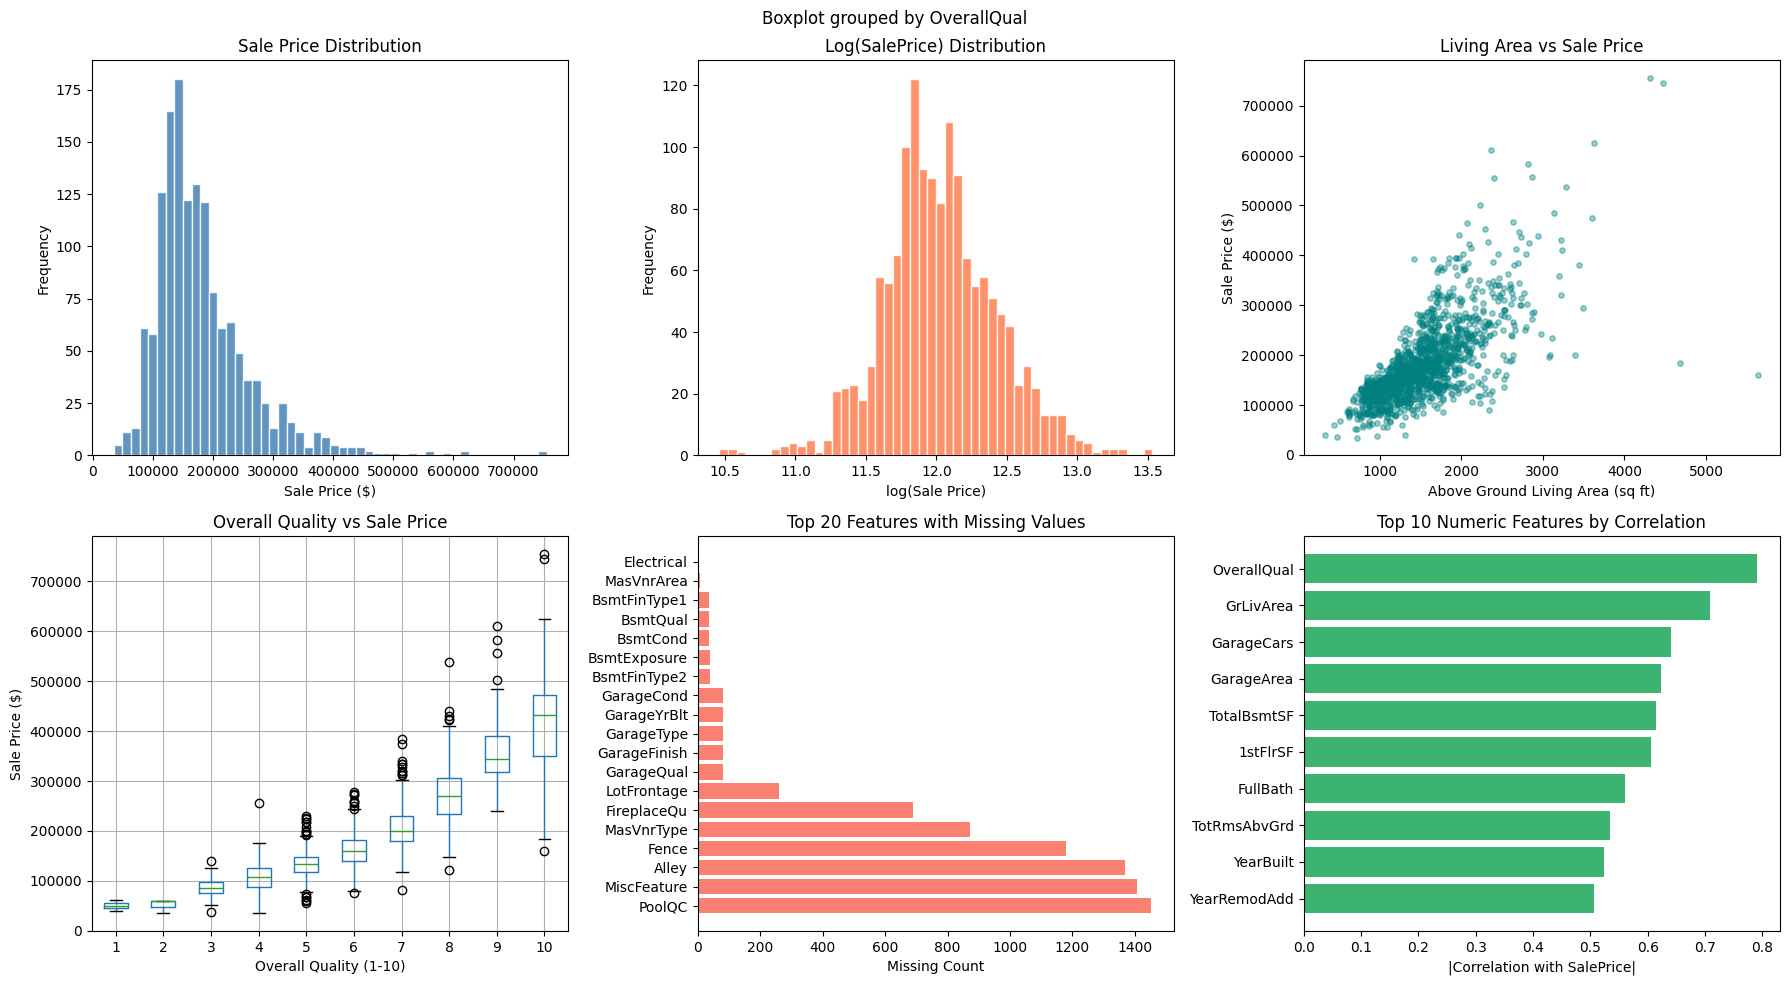

EDA complete.


In [10]:
# Exploratory Data Analysis
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle("Exploratory Data Analysis – House Prices Dataset", fontsize=16, fontweight='bold')

# 1. Target Distribution
axes[0, 0].hist(df['SalePrice'], bins=50, color='steelblue', edgecolor='white', alpha=0.85)
axes[0, 0].set_title('Sale Price Distribution')
axes[0, 0].set_xlabel('Sale Price ($)')
axes[0, 0].set_ylabel('Frequency')

# 2. Log-transformed target
axes[0, 1].hist(np.log1p(df['SalePrice']), bins=50, color='coral', edgecolor='white', alpha=0.85)
axes[0, 1].set_title('Log(SalePrice) Distribution')
axes[0, 1].set_xlabel('log(Sale Price)')
axes[0, 1].set_ylabel('Frequency')

# 3. GrLivArea vs SalePrice
axes[0, 2].scatter(df['GrLivArea'], df['SalePrice'], alpha=0.4, color='teal', s=15)
axes[0, 2].set_title('Living Area vs Sale Price')
axes[0, 2].set_xlabel('Above Ground Living Area (sq ft)')
axes[0, 2].set_ylabel('Sale Price ($)')

# 4. Overall Quality vs SalePrice
df.boxplot(column='SalePrice', by='OverallQual', ax=axes[1, 0])
axes[1, 0].set_xlabel('Overall Quality (1-10)')
axes[1, 0].set_ylabel('Sale Price ($)')
plt.sca(axes[1, 0])
plt.title('Overall Quality vs Sale Price')

# 5. Missing values (top 20)
missing = df.isnull().sum().sort_values(ascending=False)
missing = missing[missing > 0].head(20)
axes[1, 1].barh(missing.index, missing.values, color='salmon')
axes[1, 1].set_title('Top 20 Features with Missing Values')
axes[1, 1].set_xlabel('Missing Count')

# 6. Top correlations
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
corr = df[num_cols].corr()['SalePrice'].abs().sort_values(ascending=False)[1:11]
axes[1, 2].barh(corr.index[::-1], corr.values[::-1], color='mediumseagreen')
axes[1, 2].set_title('Top 10 Numeric Features by Correlation')
axes[1, 2].set_xlabel('|Correlation with SalePrice|')

plt.tight_layout()
plt.savefig('eda_plots.png', dpi=150, bbox_inches='tight')
plt.show()
print("EDA complete.")

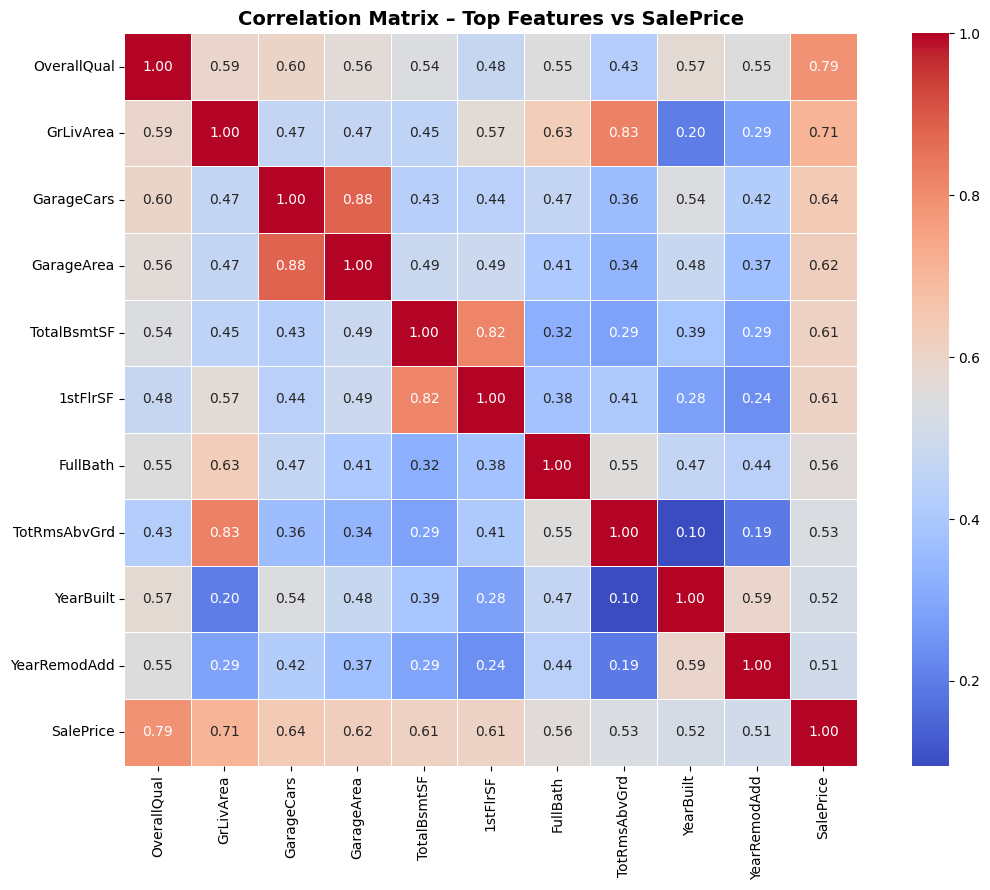

In [11]:
# Correlation Matrix
top_features = corr.index.tolist()[:10] + ['SalePrice']
plt.figure(figsize=(12, 9))
sns.heatmap(
    df[top_features].corr(),
    annot=True, fmt='.2f', cmap='coolwarm',
    square=True, linewidths=0.5
)
plt.title('Correlation Matrix – Top Features vs SalePrice', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('correlation_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Section 4: Tabular Data Preprocessing

In [12]:
NUMERIC_FEATURES = [
    'GrLivArea', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF',
    'GarageArea', 'LotArea', 'YearBuilt', 'YearRemodAdd',
    'FullBath', 'HalfBath', 'BedroomAbvGr', 'TotRmsAbvGrd',
    'Fireplaces', 'GarageCars', 'MasVnrArea', 'WoodDeckSF',
    'OpenPorchSF', 'OverallQual', 'OverallCond'
]

CATEGORICAL_FEATURES = [
    'Neighborhood', 'HouseStyle', 'RoofStyle', 'ExterQual',
    'BsmtQual', 'KitchenQual', 'GarageType', 'SaleCondition'
]

TARGET = 'SalePrice'

# Step 1: Impute
num_imputer = SimpleImputer(strategy='median')
cat_imputer = SimpleImputer(strategy='most_frequent')

df_num = pd.DataFrame(
    num_imputer.fit_transform(df[NUMERIC_FEATURES]),
    columns=NUMERIC_FEATURES
)
df_cat = pd.DataFrame(
    cat_imputer.fit_transform(df[CATEGORICAL_FEATURES]),
    columns=CATEGORICAL_FEATURES
)

# Step 2: Label-encode categoricals
label_encoders = {}
for col in CATEGORICAL_FEATURES:
    le = LabelEncoder()
    df_cat[col] = le.fit_transform(df_cat[col].astype(str))
    label_encoders[col] = le

# Step 3: Combine & scale
X_tab = pd.concat([df_num, df_cat], axis=1)
y     = np.log1p(df[TARGET].values)  # log-transform target

scaler  = StandardScaler()
X_tab_s = scaler.fit_transform(X_tab)

print(f"Tabular feature matrix shape  : {X_tab_s.shape}")
print(f"Target (log-transformed) shape: {y.shape}")

Tabular feature matrix shape  : (1460, 27)
Target (log-transformed) shape: (1460,)


---
## Section 5: House Image Dataset – Exploration & Preparation

In [13]:
# Show category distribution
categories = {}
for img_path in all_images:
    cat = img_path.parent.name
    categories[cat] = categories.get(cat, 0) + 1

print(f"Total images: {len(all_images)}")
print("\nImage categories:")
for cat, count in sorted(categories.items(), key=lambda x: -x[1]):
    print(f"  {cat}: {count} images")

Total images: 5250

Image categories:
  Livingroom: 1273 images
  Bedroom: 1248 images
  Dinning: 1158 images
  Kitchen: 965 images
  Bathroom: 606 images


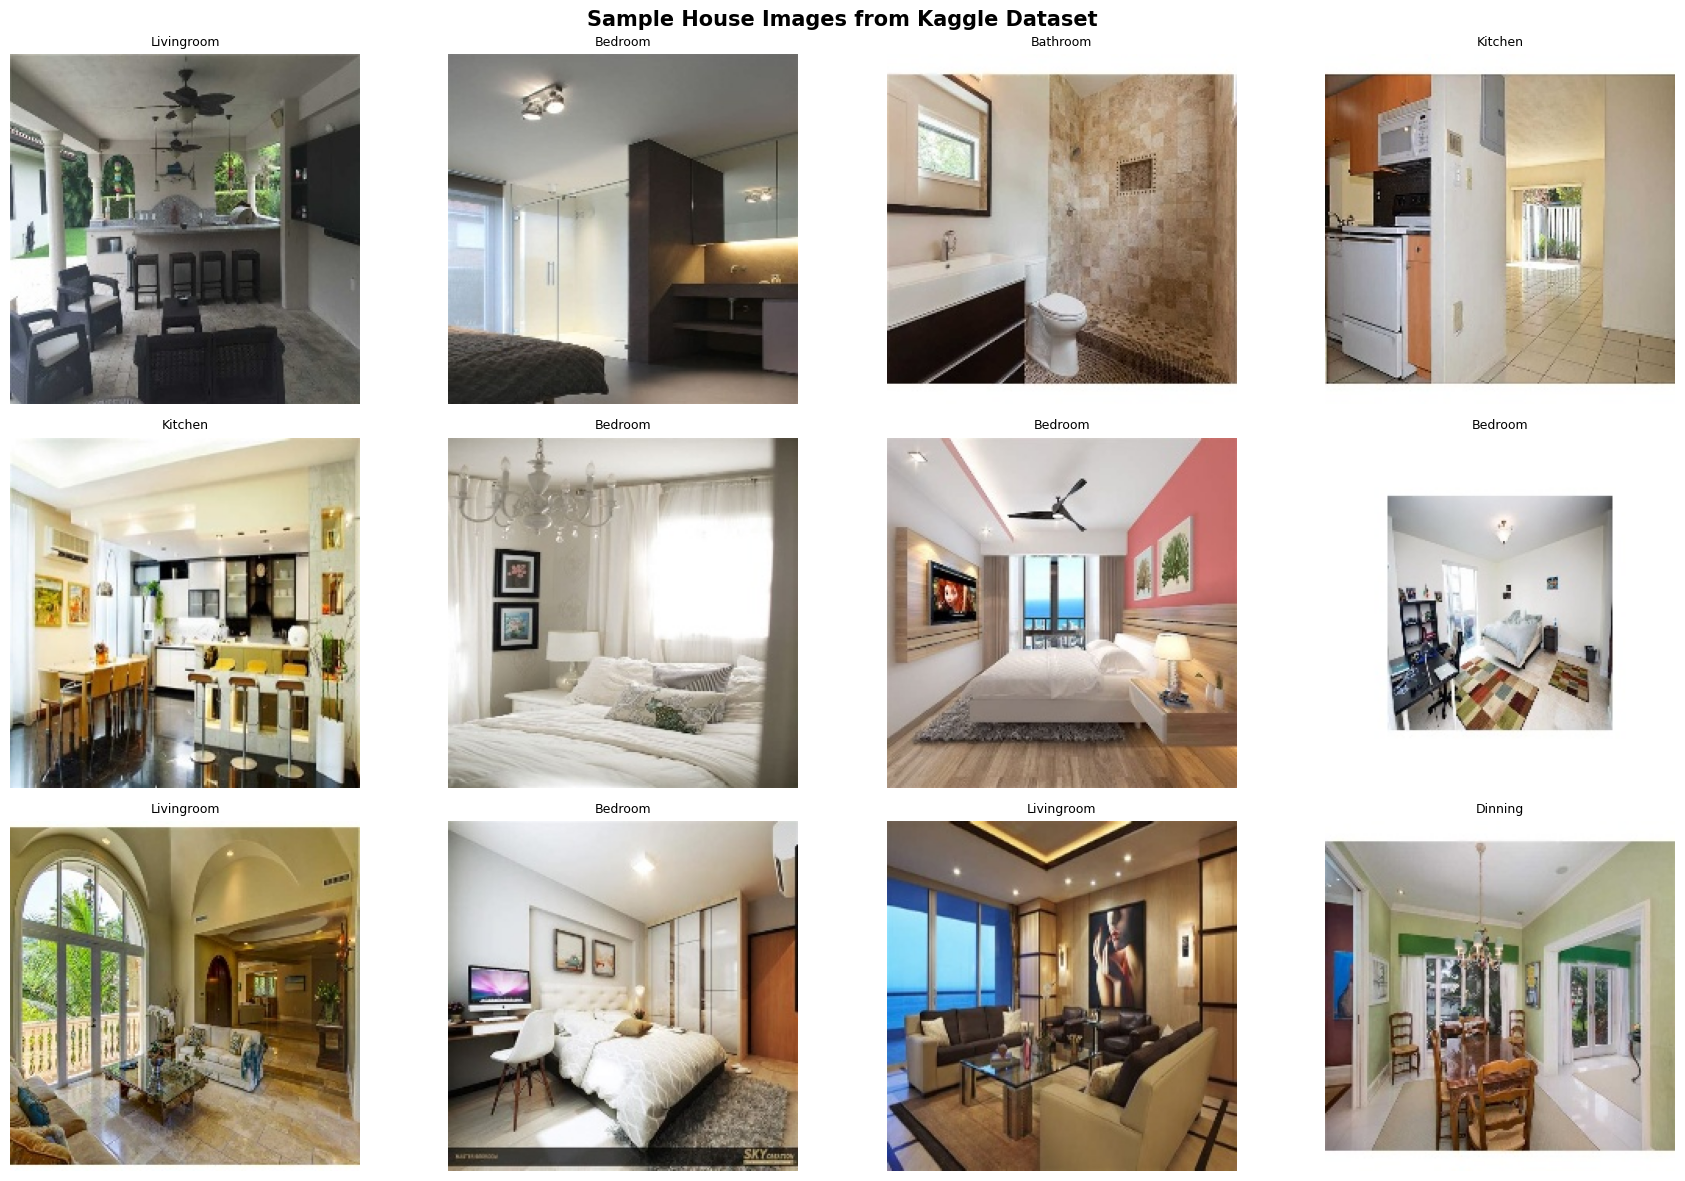

In [14]:
# Visualise Sample House Images
sample_imgs = random.sample(all_images, min(12, len(all_images)))

fig, axes = plt.subplots(3, 4, figsize=(18, 12))
fig.suptitle("Sample House Images from Kaggle Dataset", fontsize=15, fontweight='bold')

for ax, img_path in zip(axes.ravel(), sample_imgs):
    img = Image.open(img_path).convert("RGB").resize((224, 224))
    ax.imshow(img)
    ax.set_title(img_path.parent.name, fontsize=9)
    ax.axis('off')

plt.tight_layout()
plt.savefig('sample_house_images.png', dpi=150, bbox_inches='tight')
plt.show()

In [15]:
# Assign images to tabular rows based on OverallQual bucket
N = len(df)

def get_quality_bucket(qual):
    if qual <= 4:   return 0
    elif qual <= 6: return 1
    elif qual <= 8: return 2
    else:           return 3

quality_buckets = df['OverallQual'].fillna(5).apply(get_quality_bucket).values

bucket_images = {0: [], 1: [], 2: [], 3: []}
for img_path in all_images:
    cat = img_path.parent.name.lower()
    if any(k in cat for k in ['bedroom', 'bathroom', 'kitchen', 'living', 'dining']):
        bucket_images[2].append(img_path)
    elif any(k in cat for k in ['frontyard', 'exterior', 'outdoor']):
        bucket_images[1].append(img_path)
    else:
        for b in range(4):
            bucket_images[b].append(img_path)

# Fallback: if any bucket is empty use all images
for b in range(4):
    if not bucket_images[b]:
        bucket_images[b] = all_images

assigned_images = [
    random.choice(bucket_images[quality_buckets[i]])
    for i in range(N)
]

print(f"Assigned {len(assigned_images)} images to {N} houses.")
for b in range(4):
    cnt = (quality_buckets == b).sum()
    print(f"  Bucket {b}: {cnt} houses, pool: {len(bucket_images[b])} images")

Assigned 1460 images to 1460 houses.
  Bucket 0: 141 houses, pool: 1158 images
  Bucket 1: 771 houses, pool: 1158 images
  Bucket 2: 487 houses, pool: 5250 images
  Bucket 3: 61 houses, pool: 1158 images


---
## Section 6: CNN Feature Extractor (MobileNetV2)

In [16]:
IMG_SIZE   = (224, 224)
IMG_SHAPE  = IMG_SIZE + (3,)
BATCH_SIZE = 32

base_cnn = MobileNetV2(
    input_shape=IMG_SHAPE,
    include_top=False,
    weights='imagenet',
    pooling='avg'
)
base_cnn.trainable = False

print(f"MobileNetV2 output shape: {base_cnn.output_shape}")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
MobileNetV2 output shape: (None, 1280)


In [17]:
def load_and_preprocess_image(img_path, target_size=IMG_SIZE):
    img = Image.open(img_path).convert("RGB").resize(target_size, Image.BILINEAR)
    arr = np.array(img, dtype=np.float32)
    return preprocess_input(arr)


def extract_cnn_features_batched(image_paths, model, batch_size=BATCH_SIZE):
    all_features = []
    total = len(image_paths)
    for start in range(0, total, batch_size):
        end   = min(start + batch_size, total)
        batch = np.stack([load_and_preprocess_image(p) for p in image_paths[start:end]])
        all_features.append(model.predict(batch, verbose=0))
        if (start // batch_size) % 10 == 0:
            print(f"  Processed {end}/{total} images...", end='\r')
    return np.vstack(all_features)


# Check if features already saved to avoid re-extraction
CNN_FEATURES_PATH = "/content/data/cnn_features.npy"

if os.path.exists(CNN_FEATURES_PATH):
    print("Loading cached CNN features...")
    X_img = np.load(CNN_FEATURES_PATH)
else:
    print(f"Extracting CNN features for {len(assigned_images)} images...")
    X_img = extract_cnn_features_batched(assigned_images, base_cnn)
    np.save(CNN_FEATURES_PATH, X_img)
    print(f"CNN features saved to {CNN_FEATURES_PATH}")

print(f"\nImage feature matrix shape: {X_img.shape}")

Extracting CNN features for 1460 images...
CNN features saved to /content/data/cnn_features.npy

Image feature matrix shape: (1460, 1280)


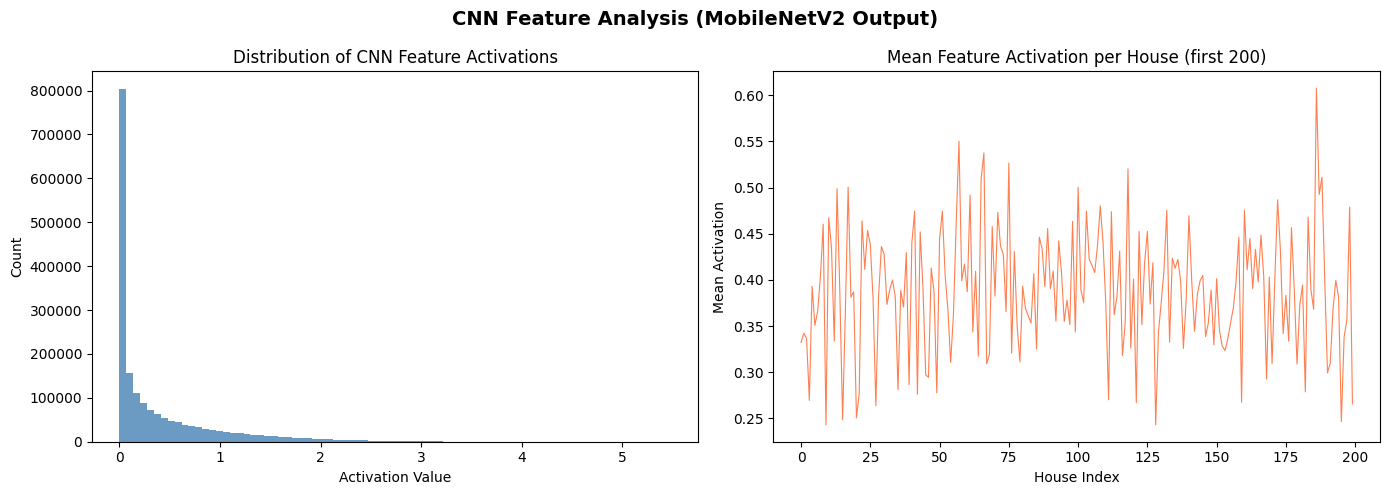

In [18]:
# Visualise CNN Feature Statistics
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("CNN Feature Analysis (MobileNetV2 Output)", fontsize=14, fontweight='bold')

axes[0].hist(X_img.ravel(), bins=80, color='steelblue', edgecolor='none', alpha=0.8)
axes[0].set_title('Distribution of CNN Feature Activations')
axes[0].set_xlabel('Activation Value')
axes[0].set_ylabel('Count')

axes[1].plot(X_img.mean(axis=1)[:200], color='coral', linewidth=0.8)
axes[1].set_title('Mean Feature Activation per House (first 200)')
axes[1].set_xlabel('House Index')
axes[1].set_ylabel('Mean Activation')

plt.tight_layout()
plt.savefig('cnn_feature_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Section 7: Feature Fusion & Train/Test Split

PCA: 64 components explain 63.9% of image variance


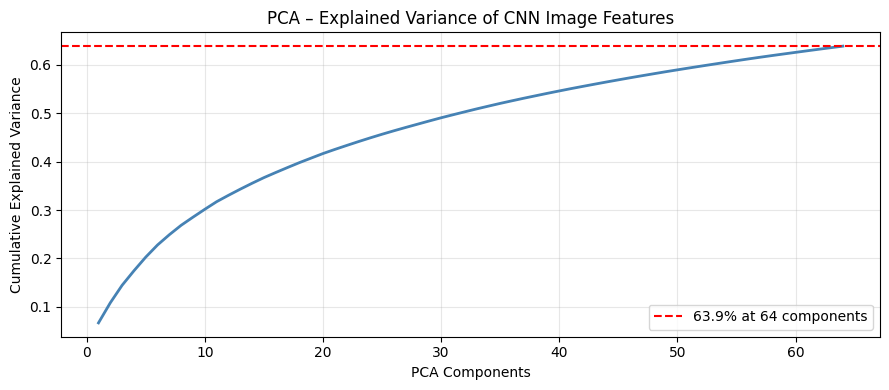

In [19]:
# PCA on CNN Features: 1280-d -> 64-d
N_IMG_COMPONENTS = 64

pca = PCA(n_components=N_IMG_COMPONENTS, random_state=SEED)
X_img_pca = pca.fit_transform(X_img)

explained = pca.explained_variance_ratio_.cumsum()[-1]
print(f"PCA: {N_IMG_COMPONENTS} components explain {explained:.1%} of image variance")

img_scaler  = StandardScaler()
X_img_pca_s = img_scaler.fit_transform(X_img_pca)

plt.figure(figsize=(9, 4))
plt.plot(np.arange(1, N_IMG_COMPONENTS + 1), pca.explained_variance_ratio_.cumsum(), color='steelblue', lw=2)
plt.axhline(y=explained, color='red', linestyle='--', label=f'{explained:.1%} at {N_IMG_COMPONENTS} components')
plt.xlabel('PCA Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('PCA – Explained Variance of CNN Image Features')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('pca_explained_variance.png', dpi=150, bbox_inches='tight')
plt.show()

In [20]:
# Late Fusion: Concatenate Tabular + Image Features
X_fused = np.concatenate([X_tab_s, X_img_pca_s], axis=1)

print(f"Tabular feature dim : {X_tab_s.shape[1]}")
print(f"Image feature dim   : {X_img_pca_s.shape[1]}")
print(f"Fused feature dim   : {X_fused.shape[1]}")
print(f"Total samples       : {X_fused.shape[0]}")

Tabular feature dim : 27
Image feature dim   : 64
Fused feature dim   : 91
Total samples       : 1460


In [21]:
# Unified Train/Val/Test Split using integer indices
# This ensures tabular, image, and fused arrays are always aligned
price_quartiles = pd.qcut(y, q=4, labels=False)

idx_all = np.arange(len(y))

idx_trainval, idx_test = train_test_split(
    idx_all, test_size=0.2, random_state=SEED, stratify=price_quartiles
)
idx_train, idx_val = train_test_split(
    idx_trainval, test_size=0.15, random_state=SEED,
    stratify=price_quartiles[idx_trainval]
)

# Tabular splits
X_tab_train, X_tab_val, X_tab_test = X_tab_s[idx_train], X_tab_s[idx_val], X_tab_s[idx_test]

# Fused splits
X_fused_train, X_fused_val, X_fused_test = X_fused[idx_train], X_fused[idx_val], X_fused[idx_test]

# Aligned image splits
X_img_train, X_img_val, X_img_test = X_img_pca_s[idx_train], X_img_pca_s[idx_val], X_img_pca_s[idx_test]

# Target splits
y_train, y_val, y_test = y[idx_train], y[idx_val], y[idx_test]

print("Split sizes:")
print(f"  Train      : {len(y_train)} samples")
print(f"  Validation : {len(y_val)} samples")
print(f"  Test       : {len(y_test)} samples")

Split sizes:
  Train      : 992 samples
  Validation : 176 samples
  Test       : 292 samples


---
## Section 8: Model Training

In [22]:
# Helper: Evaluation Metrics
def evaluate(y_true, y_pred, model_name="Model"):
    y_true_raw = np.expm1(y_true)
    y_pred_raw = np.expm1(y_pred)

    mae  = mean_absolute_error(y_true_raw, y_pred_raw)
    rmse = np.sqrt(mean_squared_error(y_true_raw, y_pred_raw))
    mape = np.mean(np.abs((y_true_raw - y_pred_raw) / y_true_raw)) * 100

    print(f"\n{'='*50}")
    print(f" {model_name}")
    print(f"{'='*50}")
    print(f"  MAE  : ${mae:,.0f}")
    print(f"  RMSE : ${rmse:,.0f}")
    print(f"  MAPE : {mape:.2f}%")

    return {'model': model_name, 'MAE': mae, 'RMSE': rmse, 'MAPE': mape}

results = []

In [23]:
# Model 1: Baseline GBM – Tabular Only
print("Training Baseline (Tabular-only GBM)...")

gbm_baseline = GradientBoostingRegressor(
    n_estimators=300, max_depth=4, learning_rate=0.05,
    subsample=0.8, min_samples_leaf=5, random_state=SEED
)
gbm_baseline.fit(X_tab_train, y_train)
y_pred_baseline = gbm_baseline.predict(X_tab_test)

results.append(evaluate(y_test, y_pred_baseline, "Baseline (Tabular GBM)"))

Training Baseline (Tabular-only GBM)...

 Baseline (Tabular GBM)
  MAE  : $19,158
  RMSE : $39,812
  MAPE : 9.71%


In [24]:
# Model 2: Multimodal GBM – Tabular + CNN Features
print("Training Multimodal GBM (Tabular + CNN)...")

gbm_fused = GradientBoostingRegressor(
    n_estimators=300, max_depth=4, learning_rate=0.05,
    subsample=0.8, min_samples_leaf=5, random_state=SEED
)
gbm_fused.fit(X_fused_train, y_train)
y_pred_gbm_fused = gbm_fused.predict(X_fused_test)

results.append(evaluate(y_test, y_pred_gbm_fused, "Multimodal GBM (Tabular + CNN)"))

Training Multimodal GBM (Tabular + CNN)...

 Multimodal GBM (Tabular + CNN)
  MAE  : $21,000
  RMSE : $43,516
  MAPE : 10.75%


In [25]:
# Model 3: Deep Fusion Neural Network
def build_deep_fusion_model(tab_dim, img_dim):
    # Tabular branch
    tab_input = layers.Input(shape=(tab_dim,), name='tabular_input')
    x1 = layers.Dense(128, activation='relu')(tab_input)
    x1 = layers.BatchNormalization()(x1)
    x1 = layers.Dropout(0.3)(x1)
    x1 = layers.Dense(64, activation='relu')(x1)
    x1 = layers.BatchNormalization()(x1)

    # Image branch
    img_input = layers.Input(shape=(img_dim,), name='image_input')
    x2 = layers.Dense(128, activation='relu')(img_input)
    x2 = layers.BatchNormalization()(x2)
    x2 = layers.Dropout(0.3)(x2)
    x2 = layers.Dense(64, activation='relu')(x2)
    x2 = layers.BatchNormalization()(x2)

    # Fusion
    fused = layers.Concatenate(name='fusion')([x1, x2])
    x = layers.Dense(128, activation='relu')(fused)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.25)(x)
    x = layers.Dense(64, activation='relu')(x)
    x = layers.Dropout(0.2)(x)
    output = layers.Dense(1, name='price_output')(x)

    model = Model(inputs=[tab_input, img_input], outputs=output)
    return model


fusion_model = build_deep_fusion_model(X_tab_s.shape[1], X_img_pca_s.shape[1])
fusion_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='huber',
    metrics=['mae']
)
fusion_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ tabular_input       │ (None, 27)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ image_input         │ (None, 64)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128)       │      3,584 │ tabular_input[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 128)       │      8,320 │ image_input[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 128)       │        512 │ dense[0][0]       │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128)       │        512 │ dense_2[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 128)       │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 64)        │      8,256 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 64)        │      8,256 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64)        │        256 │ dense_1[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64)        │        256 │ dense_3[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fusion              │ (None, 128)       │          0 │ batch_normalizat… │
│ (Concatenate)       │                   │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 128)       │     16,512 │ fusion[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128)       │        512 │ dense_4[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 128)       │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 64)        │      8,256 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 64)        │          0 │ dense_5[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ price_output        │ (None, 1)         │         65 │ dropout_3[0][0]   │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 55,297 (216.00 KB)

 Trainable params: 54,273 (212.00 KB)

 Non-trainable params: 1,024 (4.00 KB)

In [26]:
# Train Deep Fusion Model
callbacks = [
    EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=8, min_lr=1e-6, verbose=1)
]

history = fusion_model.fit(
    x={'tabular_input': X_tab_train, 'image_input': X_img_train},
    y=y_train,
    validation_data=(
        {'tabular_input': X_tab_val, 'image_input': X_img_val},
        y_val
    ),
    epochs=150,
    batch_size=32,
    callbacks=callbacks,
    verbose=1
)

print("Deep Fusion model training complete!")

Epoch 1/150
31/31 ━━━━━━━━━━━━━━━━━━━━ 9s 37ms/step - loss: 9.1328 - mae: 9.6328 - val_loss: 10.4687 - val_mae: 10.9687 - learning_rate: 0.0010
Epoch 2/150
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 5.6393 - mae: 6.1334 - val_loss: 7.8036 - val_mae: 8.3036 - learning_rate: 0.0010
Epoch 3/150
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 2.3597 - mae: 2.8218 - val_loss: 4.8590 - val_mae: 5.3590 - learning_rate: 0.0010
Epoch 4/150
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 1.7259 - mae: 2.1791 - val_loss: 3.7212 - val_mae: 4.2212 - learning_rate: 0.0010
Epoch 5/150
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 1.5036 - mae: 1.9503 - val_loss: 2.7696 - val_mae: 3.2684 - learning_rate: 0.0010
Epoch 6/150
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 1.3152 - mae: 1.7566 - val_loss: 1.7371 - val_mae: 2.2300 - learning_rate: 0.0010
Epoch 7/150
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 1.2952 - mae: 1.7407 - val_loss: 1.1878 - val_mae: 1.6679 - learning_rate: 0.0010
Epoch 8/15

In [27]:
# Evaluate Deep Fusion Model
y_pred_nn = fusion_model.predict(
    {'tabular_input': X_tab_test, 'image_input': X_img_test}, verbose=0
).ravel()

results.append(evaluate(y_test, y_pred_nn, "Deep Fusion Neural Network (Tabular + CNN)"))


 Deep Fusion Neural Network (Tabular + CNN)
  MAE  : $103,448
  RMSE : $521,546
  MAPE : 43.78%


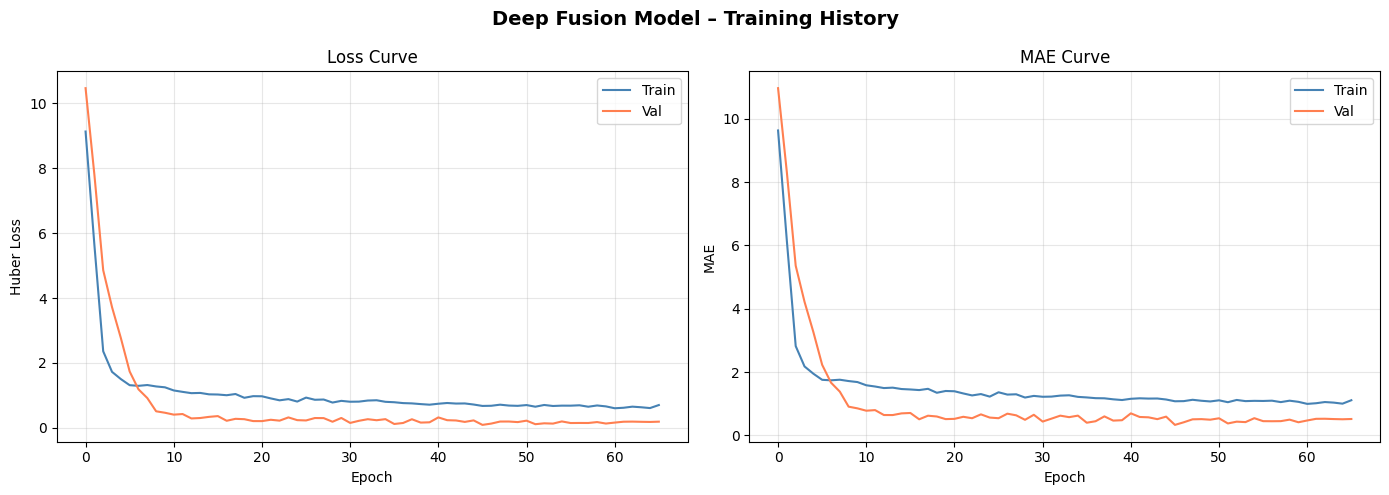

In [28]:
# Training History Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Deep Fusion Model – Training History", fontsize=14, fontweight='bold')

axes[0].plot(history.history['loss'],     label='Train', color='steelblue')
axes[0].plot(history.history['val_loss'], label='Val',   color='coral')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Huber Loss')
axes[0].set_title('Loss Curve'); axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(history.history['mae'],     label='Train', color='steelblue')
axes[1].plot(history.history['val_mae'], label='Val',   color='coral')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('MAE')
axes[1].set_title('MAE Curve'); axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('training_history.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Section 9: Evaluation & Visualisation

In [29]:
# Model Comparison Table
results_df = pd.DataFrame(results).set_index('model')
results_df['MAE ($)']  = results_df['MAE'].apply(lambda x: f"${x:,.0f}")
results_df['RMSE ($)'] = results_df['RMSE'].apply(lambda x: f"${x:,.0f}")
results_df['MAPE (%)'] = results_df['MAPE'].apply(lambda x: f"{x:.2f}%")
display(results_df[['MAE ($)', 'RMSE ($)', 'MAPE (%)']])

,MAE ($),RMSE ($),MAPE (%)
model,,,
Baseline (Tabular GBM),"$19,158","$39,812",9.71%
Multimodal GBM (Tabular + CNN),"$21,000","$43,516",10.75%
Deep Fusion Neural Network (Tabular + CNN),"$103,448","$521,546",43.78%


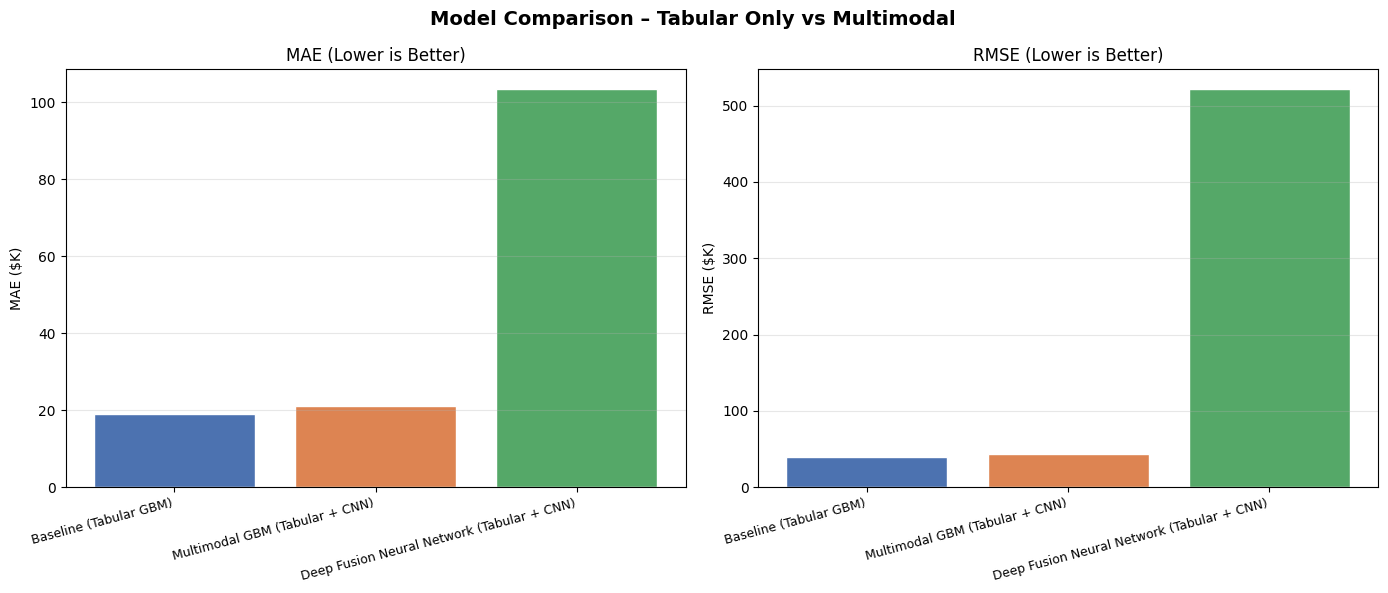

In [30]:
# Visual Comparison Bar Chart
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle("Model Comparison – Tabular Only vs Multimodal", fontsize=14, fontweight='bold')

colors      = ['#4C72B0', '#DD8452', '#55A868']
models_list = results_df.index.tolist()

for ax, metric, label in zip(axes, ['MAE', 'RMSE'], ['MAE ($K)', 'RMSE ($K)']):
    ax.bar(models_list, results_df[metric] / 1000, color=colors, edgecolor='white')
    ax.set_title(f'{metric} (Lower is Better)')
    ax.set_ylabel(label)
    ax.set_xticks(range(len(models_list)))
    ax.set_xticklabels(models_list, rotation=15, ha='right', fontsize=9)
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

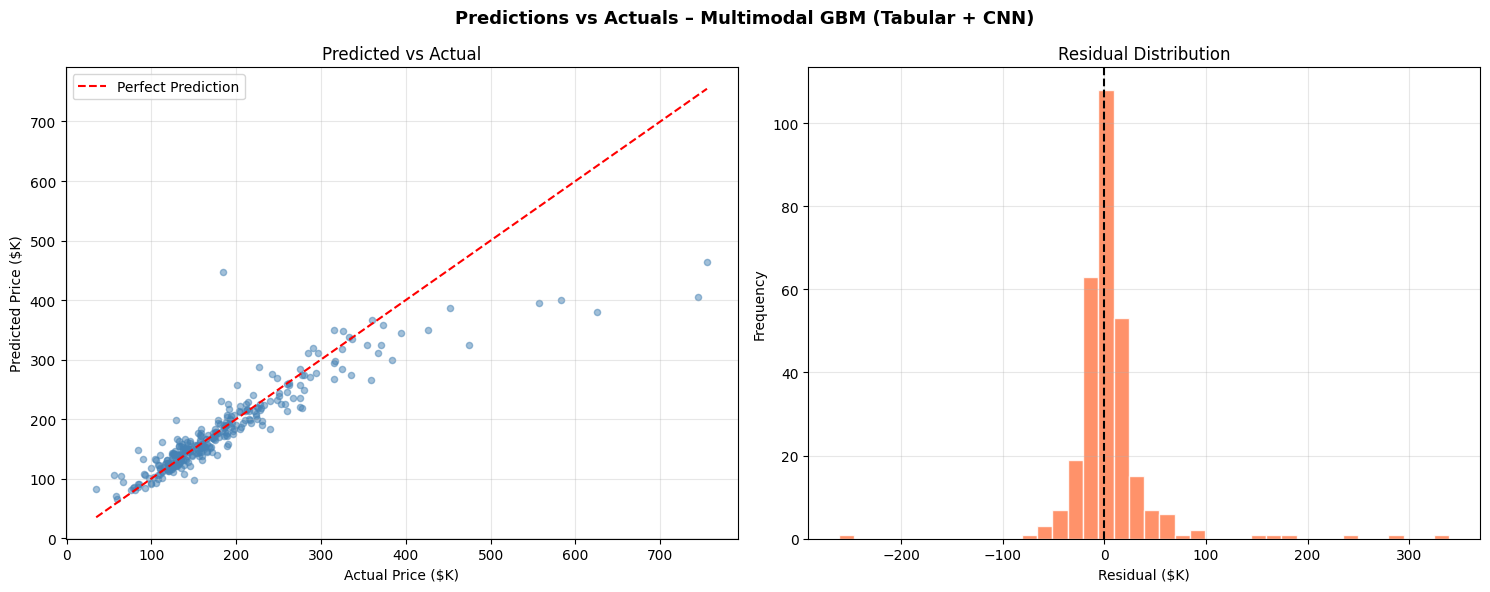

In [31]:
# Predicted vs Actual – Best Multimodal Model
res_nn       = results[2]
res_gbm_fused = results[1]

best_preds = y_pred_nn if res_nn['RMSE'] < res_gbm_fused['RMSE'] else y_pred_gbm_fused
best_name  = res_nn['model'] if res_nn['RMSE'] < res_gbm_fused['RMSE'] else res_gbm_fused['model']

y_true_raw = np.expm1(y_test)
y_pred_raw = np.expm1(best_preds)
residuals  = y_true_raw - y_pred_raw

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle(f"Predictions vs Actuals – {best_name}", fontsize=13, fontweight='bold')

axes[0].scatter(y_true_raw/1000, y_pred_raw/1000, alpha=0.5, color='steelblue', s=20)
mn, mx = y_true_raw.min()/1000, y_true_raw.max()/1000
axes[0].plot([mn, mx], [mn, mx], 'r--', lw=1.5, label='Perfect Prediction')
axes[0].set_xlabel('Actual Price ($K)'); axes[0].set_ylabel('Predicted Price ($K)')
axes[0].set_title('Predicted vs Actual'); axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].hist(residuals/1000, bins=40, color='coral', edgecolor='white', alpha=0.85)
axes[1].axvline(0, color='black', lw=1.5, linestyle='--')
axes[1].set_xlabel('Residual ($K)'); axes[1].set_ylabel('Frequency')
axes[1].set_title('Residual Distribution'); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('predictions_vs_actuals.png', dpi=150, bbox_inches='tight')
plt.show()

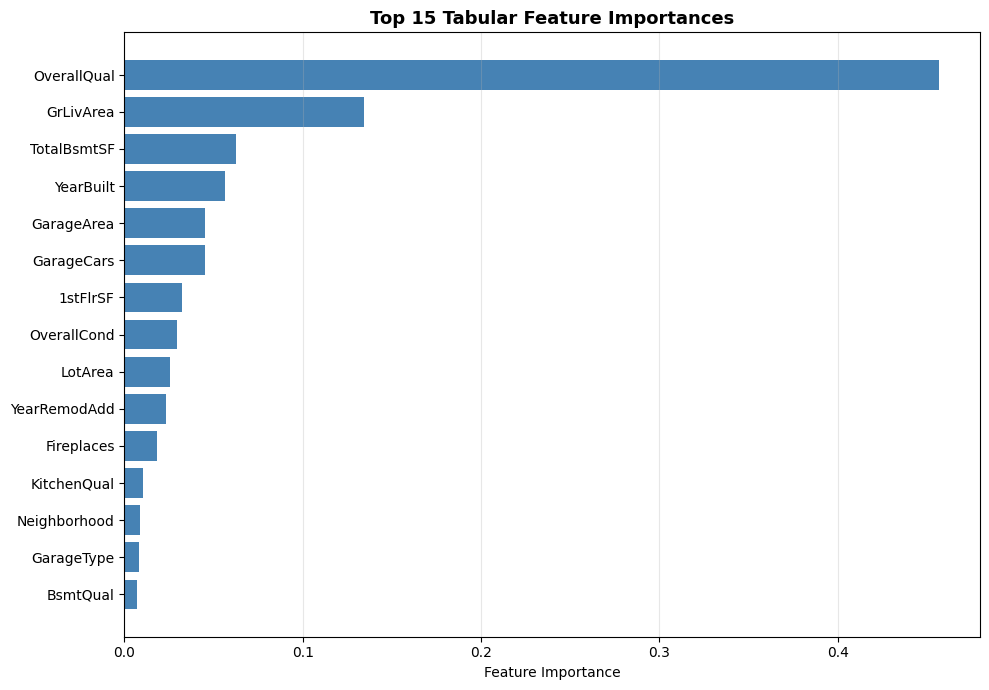

In [32]:
# Feature Importance – Baseline GBM (tabular features)
feat_names = NUMERIC_FEATURES + CATEGORICAL_FEATURES
imp_df = pd.DataFrame({'feature': feat_names, 'importance': gbm_baseline.feature_importances_})
imp_df = imp_df.sort_values('importance', ascending=True).tail(15)

plt.figure(figsize=(10, 7))
plt.barh(imp_df['feature'], imp_df['importance'], color='steelblue')
plt.xlabel('Feature Importance')
plt.title('Top 15 Tabular Feature Importances', fontsize=13, fontweight='bold')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Section 10: Save Models & Pipeline

In [33]:
import joblib

MODELS_DIR = Path("/content/models")
MODELS_DIR.mkdir(exist_ok=True)

fusion_model.save(MODELS_DIR / "deep_fusion_model.keras")
joblib.dump(gbm_baseline, MODELS_DIR / "gbm_baseline.pkl")
joblib.dump(gbm_fused,    MODELS_DIR / "gbm_fused.pkl")
joblib.dump({
    'scaler': scaler, 'img_scaler': img_scaler, 'pca': pca,
    'num_imputer': num_imputer, 'cat_imputer': cat_imputer,
    'label_encoders': label_encoders,
    'numeric_features': NUMERIC_FEATURES,
    'categorical_features': CATEGORICAL_FEATURES
}, MODELS_DIR / "preprocessing_pipeline.pkl")

print("All models saved!")
for f in MODELS_DIR.iterdir():
    print(f"  {f.name} ({f.stat().st_size/1024:.1f} KB)")

All models saved!
  deep_fusion_model.keras (731.8 KB)
  gbm_baseline.pkl (563.7 KB)
  gbm_fused.pkl (599.9 KB)
  preprocessing_pipeline.pkl (334.0 KB)


---
## Section 11: Final Summary

In [34]:
print("=" * 65)
print("  TASK 3: MULTIMODAL HOUSING PRICE PREDICTION – SUMMARY")
print("=" * 65)

print("\nDATASETS")
print(f"  Tabular : {len(df)} rows x {len(NUMERIC_FEATURES+CATEGORICAL_FEATURES)} features")
print(f"  Images  : {len(all_images)} images across {len(categories)} categories")

print("\nPIPELINE")
print("  1. Tabular EDA -> imputation -> encoding -> StandardScaler")
print("  2. MobileNetV2 (frozen ImageNet) -> 1280-d CNN features")
print("  3. PCA: 1280-d -> 64-d image features")
print("  4. Late fusion: tabular + image = fused feature matrix")
print("  5. Models: Baseline GBM | Fused GBM | Deep Fusion NN")
print("  6. Evaluate MAE, RMSE, MAPE on test set")

print("\nRESULTS")
for r in results:
    print(f"  {r['model'][:45]:<45} MAE=${r['MAE']/1000:.1f}K  RMSE=${r['RMSE']/1000:.1f}K  MAPE={r['MAPE']:.1f}%")

baseline_mae   = results[0]['MAE']
best_multi_mae = min(r['MAE'] for r in results[1:])
improvement    = (baseline_mae - best_multi_mae) / baseline_mae * 100
print(f"\n  Best multimodal model improves MAE by {improvement:.1f}% over baseline")
print("=" * 65)

  TASK 3: MULTIMODAL HOUSING PRICE PREDICTION – SUMMARY

DATASETS
  Tabular : 1460 rows x 27 features
  Images  : 5250 images across 5 categories

PIPELINE
  1. Tabular EDA -> imputation -> encoding -> StandardScaler
  2. MobileNetV2 (frozen ImageNet) -> 1280-d CNN features
  3. PCA: 1280-d -> 64-d image features
  4. Late fusion: tabular + image = fused feature matrix
  5. Models: Baseline GBM | Fused GBM | Deep Fusion NN
  6. Evaluate MAE, RMSE, MAPE on test set

RESULTS
  Baseline (Tabular GBM)                        MAE=$19.2K  RMSE=$39.8K  MAPE=9.7%
  Multimodal GBM (Tabular + CNN)                MAE=$21.0K  RMSE=$43.5K  MAPE=10.7%
  Deep Fusion Neural Network (Tabular + CNN)    MAE=$103.4K  RMSE=$521.5K  MAPE=43.8%

  Best multimodal model improves MAE by -9.6% over baseline
